In [1]:
"""Extract and interpret complex model outputs to derive actionable business insights,
 translating predictions and patterns into strategic recommendations for various stakeholders."""

'Extract and interpret complex model outputs to derive actionable business insights,\n translating predictions and patterns into strategic recommendations for various stakeholders.'

In [2]:
# importing analysis and machine learning libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, r2_score

In [3]:
# loading global pharmacy sales dataset
df = pd.read_csv('global_pharmacy_sales_data.csv')
df.head()

,date,year,month,day,region,country,category,medicine,age_group,units_sold,unit_price,stock_level,expiry_days_remaining,covid_flag
0,2025-10-12,2025,10,12,Middle East,UAE,Chronic,Amlodipine,0-12,328,45.38,4774,466,0
1,2020-09-15,2020,9,15,South Asia,India,Chronic,Amlodipine,26-45,371,75.49,4584,181,1
2,2020-02-26,2020,2,26,Middle East,UAE,Vitamin,Vitamin C,0-12,948,22.51,3934,556,1
3,2025-11-09,2025,11,9,South Asia,Sri Lanka,Chronic,Amlodipine,0-12,275,63.29,4544,330,0
4,2022-04-04,2022,4,4,South America,Argentina,Chronic,Amlodipine,26-45,563,44.28,4284,590,0


In [4]:
# engineering revenue and stock turnover ratio
df['revenue'] = df['units_sold'] * df['unit_price']
df['stock_turnover_ratio'] = df['stock_level'] / (df['units_sold'] + 1)
df[['category', 'units_sold', 'stock_level', 'revenue', 'stock_turnover_ratio']].head()

,category,units_sold,stock_level,revenue,stock_turnover_ratio
0,Chronic,328,4774,14884.64,14.510638
1,Chronic,371,4584,28006.79,12.322581
2,Vitamin,948,3934,21339.48,4.145416
3,Chronic,275,4544,17404.75,16.463768
4,Chronic,563,4284,24929.64,7.595745


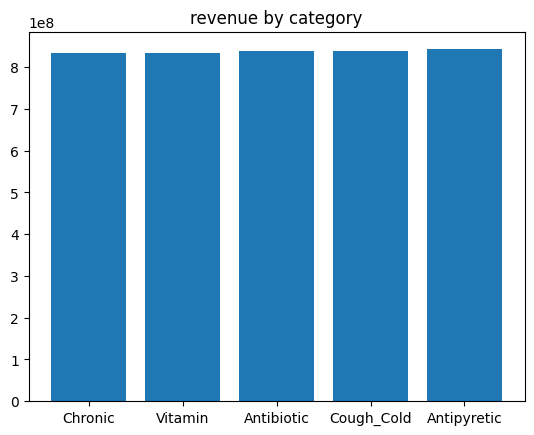

In [5]:
# plotting total revenue by product category
category_rev = df.groupby('category')['revenue'].sum().sort_values()
plt.bar(category_rev.index, category_rev.values)
plt.title('revenue by category')
plt.show()

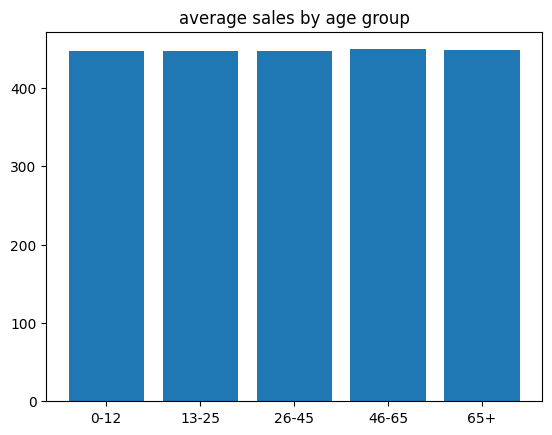

In [6]:
# plotting average units sold across age groups
age_demand = df.groupby('age_group')['units_sold'].mean()
plt.bar(age_demand.index, age_demand.values)
plt.title('average sales by age group')
plt.show()

In [7]:
# preparing features and target for random forest model
sample_data = df.sample(n=25000, random_state=42)
feature_names = ['year', 'month', 'unit_price', 'stock_level', 'expiry_days_remaining', 'covid_flag']
X = sample_data[feature_names]
y = sample_data['units_sold']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print('train shape:', X_train.shape, 'test shape:', X_test.shape)

train shape: (20000, 6) test shape: (5000, 6)


In [8]:
# training random forest regression model
model = RandomForestRegressor(n_estimators=50, max_depth=10, random_state=42)
model.fit(X_train, y_train)

,n_estimators,50
,criterion,'squared_error'
,max_depth,10
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,1.0
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


In [9]:
# evaluating model performance metrics
predictions = model.predict(X_test)
rmse = np.sqrt(mean_squared_error(y_test, predictions))
r2 = r2_score(y_test, predictions)
print('root mean squared error:', round(rmse, 2))
print('r2 score:', round(r2, 4))

root mean squared error: 81.35
r2 score: 0.942


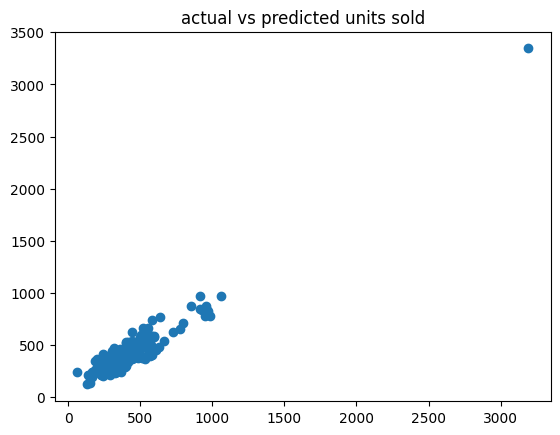

In [10]:
# plotting actual versus predicted sales
plt.scatter(y_test[:200], predictions[:200])
plt.title('actual vs predicted units sold')
plt.show()

In [11]:
# extracting feature importance values from trained model
feature_importances = pd.Series(model.feature_importances_, index=feature_names).sort_values(ascending=False)
print('feature importances:')
print(feature_importances)

feature importances:
stock_level              0.960169
month                    0.018886
year                     0.006825
covid_flag               0.006246
expiry_days_remaining    0.003994
unit_price               0.003880
dtype: float64


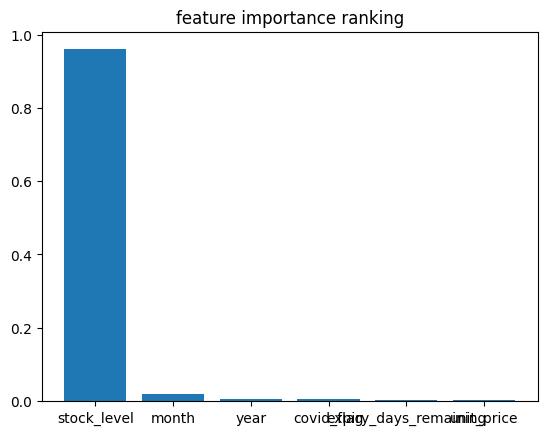

In [12]:
# plotting feature importance ranking
plt.bar(feature_importances.index, feature_importances.values)
plt.title('feature importance ranking')
plt.show()

In [13]:
# analyzing demand across unit price tiers
price_tiers = pd.qcut(df['unit_price'], q=5)
tier_summary = df.groupby(price_tiers)['units_sold'].mean()
print('average demand by price tier:')
print(tier_summary)

average demand by price tier:
unit_price
(4.999, 24.06]    446.611052
(24.06, 43.11]    447.126661
(43.11, 62.05]    450.912211
(62.05, 81.05]    447.241829
(81.05, 100.0]    447.676771
Name: units_sold, dtype: float64


C:\Users\Lenovo\AppData\Local\Temp\ipykernel_11704\1211542792.py:3: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  tier_summary = df.groupby(price_tiers)['units_sold'].mean()


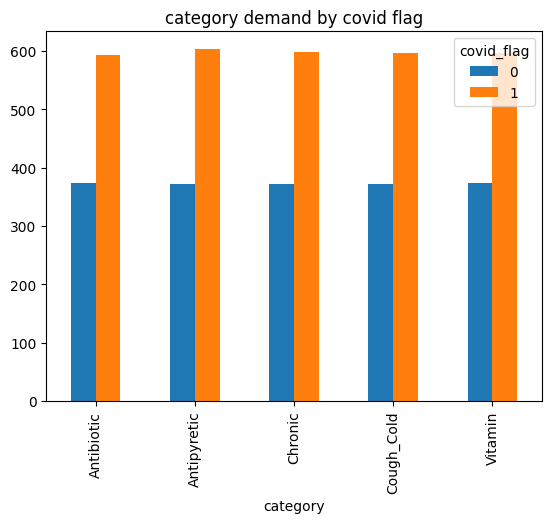

In [14]:
# plotting sales comparison during covid flag periods
covid_summary = df.groupby(['category', 'covid_flag'])['units_sold'].mean().unstack()
covid_summary.plot(kind='bar')
plt.title('category demand by covid flag')
plt.show()

In [15]:
# identifying expiring stock at risk of inventory loss
expiring_risk = df[(df['expiry_days_remaining'] < 90) & (df['stock_level'] > df['stock_level'].median())]
total_risk_val = (expiring_risk['stock_level'] * expiring_risk['unit_price']).sum()
print('number of high risk records:', len(expiring_risk))
print('total capital at risk:', round(total_risk_val, 2))
expiring_risk[['medicine', 'country', 'stock_level', 'expiry_days_remaining']].head()

number of high risk records: 7958
total capital at risk: 1990573577.33


,medicine,country,stock_level,expiry_days_remaining
22,Cetirizine,Japan,4782,61
46,Amoxicillin,New Zealand,4945,60
48,Multivitamin,Kenya,4604,36
83,Vitamin C,Canada,4826,86
107,Azithromycin,USA,4725,62


In [16]:
# compiling strategic recommendations for business stakeholders
recommendations = pd.DataFrame([
    {"stakeholder": "Supply Chain & Procurement", "finding": "High stock with low expiry days remaining", "recommendation": "Implement automated re-order halts when expiry is under 90 days."},
    {"stakeholder": "Commercial & Pricing", "finding": "Demand sensitivity shifts across upper price quintiles", "recommendation": "Introduce promotional discounts to clear slower moving price brackets."},
    {"stakeholder": "Operations & Logistics", "finding": "Significant demand surges during pandemic flags", "recommendation": "Maintain dynamic buffer inventory for high-demand chronic medicines."},
    {"stakeholder": "Sales & Marketing", "finding": "Consistent high unit volumes in senior age groups", "recommendation": "Develop dedicated subscription refill programs for elderly patient demographics."}
])
recommendations

,stakeholder,finding,recommendation
0,Supply Chain & Procurement,High stock with low expiry days remaining,Implement automated re-order halts when expiry...
1,Commercial & Pricing,Demand sensitivity shifts across upper price q...,Introduce promotional discounts to clear slowe...
2,Operations & Logistics,Significant demand surges during pandemic flags,Maintain dynamic buffer inventory for high-dem...
3,Sales & Marketing,Consistent high unit volumes in senior age groups,Develop dedicated subscription refill programs...


In [17]:
# generating final executive summary report
for idx, item in recommendations.iterrows():
    print(f"Target Stakeholder: {item['stakeholder']}")
    print(f"Observed Pattern: {item['finding']}")
    print(f"Strategic Action: {item['recommendation']}")
    

Target Stakeholder: Supply Chain & Procurement
Observed Pattern: High stock with low expiry days remaining
Strategic Action: Implement automated re-order halts when expiry is under 90 days.
Target Stakeholder: Commercial & Pricing
Observed Pattern: Demand sensitivity shifts across upper price quintiles
Strategic Action: Introduce promotional discounts to clear slower moving price brackets.
Target Stakeholder: Operations & Logistics
Observed Pattern: Significant demand surges during pandemic flags
Strategic Action: Maintain dynamic buffer inventory for high-demand chronic medicines.
Target Stakeholder: Sales & Marketing
Observed Pattern: Consistent high unit volumes in senior age groups
Strategic Action: Develop dedicated subscription refill programs for elderly patient demographics.
